In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('1-uber.csv')

In [3]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [4]:
df.dtypes

Unnamed: 0             int64
key                      str
fare_amount          float64
pickup_datetime          str
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object

In [5]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [6]:
df.isna().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [7]:
df.drop(columns=["Unnamed: 0", "key"], inplace=True) # remove unnecessary columns
df.dropna(inplace=True) # remove rows that have null values
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [8]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime']).dt.strftime("%H").astype('float32')
df = df.rename(columns={"pickup_datetime" : "time"})

In [9]:
import math
def euclidian_distance(lat1, lon1, lat2, lon2):
    dlat = lat2 - lat1
    dlon = lon2 - lon1 
    distance = math.sqrt(dlat**2 + dlon**2)
    return distance

df['distance'] = df.apply(
    lambda row : euclidian_distance(
        row['pickup_latitude'],
        row['pickup_longitude'],
        row['dropoff_latitude'],
        row['dropoff_longitude']
    ), axis=1
)

<Axes: xlabel='passenger_count', ylabel='fare_amount'>

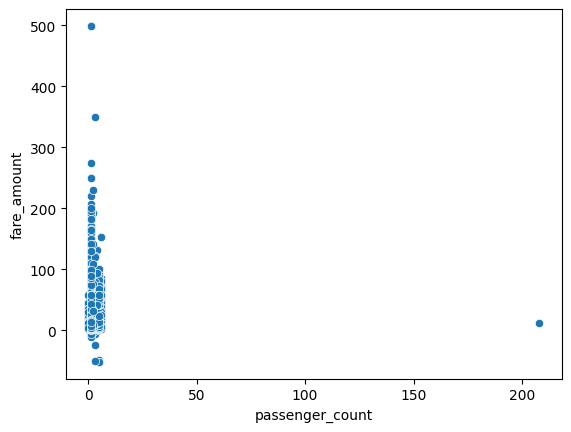

In [10]:
# Outlier Analysis

sns.scatterplot(df, x='passenger_count', y='fare_amount')

Text(0.5, 1.0, 'Fare Amount')

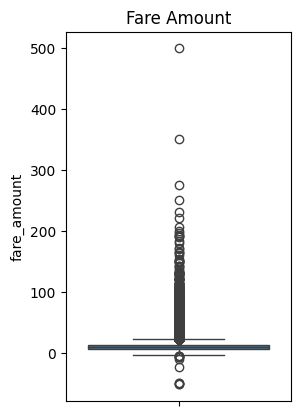

In [11]:
plt.subplot(1, 2, 1)

sns.boxplot(y=df['fare_amount'])

plt.title('Fare Amount')

In [12]:
def remove_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df = df[
        (df[column] >= lower_bound) &
        (df[column] <= upper_bound)
    ]
    return df

df = remove_outliers(df, 'fare_amount')
df = remove_outliers(df, 'distance')

In [13]:
# Correlation Check
df.corr(method="pearson")

,fare_amount,time,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance
fare_amount,1.000000,0.009587,0.014097,-0.013782,0.014168,-0.013934,0.016654,0.756315
time,0.009587,1.000000,0.000611,-0.000989,0.000587,-0.001004,0.015056,-0.012282
pickup_longitude,0.014097,0.000611,1.000000,-0.984186,0.999999,-0.984186,-0.001086,-0.210570
pickup_latitude,-0.013782,-0.000989,-0.984186,1.000000,-0.984188,0.999994,-0.000562,0.198468
dropoff_longitude,0.014168,0.000587,0.999999,-0.984188,1.000000,-0.984185,-0.001085,-0.210427
dropoff_latitude,-0.013934,-0.001004,-0.984186,0.999994,-0.984185,1.000000,-0.000557,0.198462
passenger_count,0.016654,0.015056,-0.001086,-0.000562,-0.001085,-0.000557,1.000000,0.003801
distance,0.756315,-0.012282,-0.210570,0.198468,-0.210427,0.198462,0.003801,1.000000


In [14]:
# Model Fitting
# Linear Regression

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('fare_amount', axis=1)
y = df['fare_amount']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [15]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

In [16]:
from sklearn.metrics import r2_score
from sklearn.metrics import root_mean_squared_error

print("R2 Score: ", r2_score(y_pred, y_test))
print("RMSE: ", root_mean_squared_error(y_pred, y_test))

R2 Score:  0.34874730478876026
RMSE:  2.3370134781646708


In [17]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

In [18]:
from sklearn.metrics import r2_score
from sklearn.metrics import root_mean_squared_error

print("R2 score: ", r2_score(y_test, y_pred))
print("RMSE: ", root_mean_squared_error(y_test, y_pred))

R2 score:  0.6688858821584622
RMSE:  2.148327843316881
